#### Структура файла `FONT.BIN`:
- `0x0000 - 0x001F`: Пусто (32 байта нулей)
- `0x0020 - 0x035F`: Английский алфавит 16x16 (832 байт) - A-Z (832 / 32 = 26 символов)
- `0x0360 - 0x061F`: Пусто (704 байта)
- `0x0620 - 0x095F`: Английский алфавит 8x16 (832 байта) 
- `0x0960 - 0x0A7F`: Пусто (288 байт)
- `0x0A80 - 0x`
- `0x0C10 - ... `: Следующие блоки

#### Пытаюсь разобрать область `0x0020 - 0x035F`

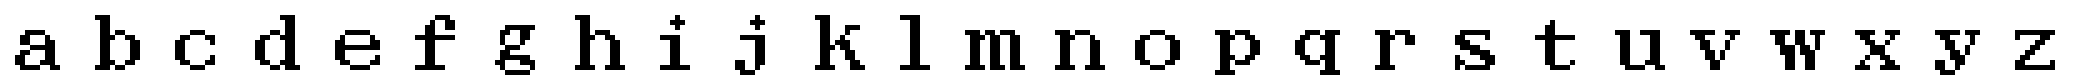

In [25]:
import os
from PIL import Image, ImageDraw
from IPython.display import display

with open('Data/FONT.BIN', 'rb') as f:
    data = f.read()

start = 0x020
char_size = 32
char_width = 16
char_height = 16
    
# Создаем изображение 256x16 (32 символа * 8 пикселей = 256)
img = Image.new('1', (416, 16), 1)  # 1 - белый фон (mode '1' - черно-белое)
pixels = img.load()    

for char in range(26):  # 0-25
    
    row_in_image = 0  
    col_in_image = char * char_width
    
    for row in range(char_height):  
        pos = start + char * char_size + row * 2
        if pos + 1 >= len(data):
            break
            
        byte1 = data[pos]  
        byte2 = data[pos + 1]
        
        for col in range(8):
            if byte1 & (1 << (7-col)):  # Если бит установлен
                x = col_in_image + col
                y = row_in_image + row
                if x < 416 and y < 32:  # Проверяем границы изображения
                    pixels[x, y] = 0  # 0 - черный цвет
                    
        for col in range(8):
            if byte2 & (1 << (7-col)):  # Если бит установлен
                x = col_in_image + col + 8
                y = row_in_image + row
                if x < 416 and y < 32:  # Проверяем границы изображения
                    pixels[x, y] = 0  # 0 - черный цвет
        

img.save('Result/font_output_0x0020-0x035F.png')

new_width = img.width * 5
new_height = img.height * 5
img_resized = img.resize((new_width, new_height), Image.Resampling.NEAREST)  # NEAREST лучше для пиксельной графики

display(img_resized)

#### Пытаюсь разобрать область `0x0620 - 0x095F` - английский алфавит

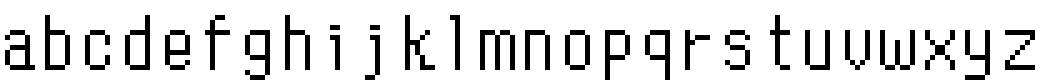

In [26]:
import os
from PIL import Image
from IPython.display import display

with open('Data/FONT.BIN', 'rb') as f:
    data = f.read()

start = 0x620
char_size = 32
char_width = 8
char_height = 16

# Создаем изображение 256x16 (32 символа * 8 пикселей = 256)
img = Image.new('1', (208, 16), 1)  # 1 - белый фон (mode '1' - черно-белое)
pixels = img.load()

for char in range(26):  # 0-25
    
    row_in_image = 0  
    col_in_image = char * char_width
    
    for row in range(char_height):  
        pos = start + char * char_size + row * 2
        if pos + 1 >= len(data):
            break
            
        byte = data[pos]  
        
        
        for col in range(8):
            if byte & (1 << (7-col)):  # Если бит установлен
                x = col_in_image + col
                y = row_in_image + row
                if x < 256 and y < 16:  # Проверяем границы изображения
                    pixels[x, y] = 0  # 0 - черный цвет

img.save('Result/font_output_0x0620-0x095F.png')

new_width = img.width * 5
new_height = img.height * 5
img_resized = img.resize((new_width, new_height), Image.Resampling.NEAREST)  # NEAREST лучше для пиксельной графики

display(img_resized)

#### В итоге в области позиции 0x620 - 0x960 находится английский алфавит

#### Пытаюсь разобрать область `0x0A80 - 0x0BFF`

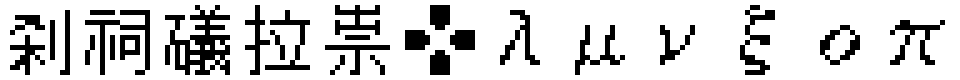

In [28]:
import os
from PIL import Image, ImageDraw
from IPython.display import display

with open('Data/FONT.BIN', 'rb') as f:
    data = f.read()

start = 0xA80
char_size = 32
char_width = 16
char_height = 16
    
# Создаем изображение 256x16 (32 символа * 8 пикселей = 256)
img = Image.new('1', (192, 16), 1)  # 1 - белый фон (mode '1' - черно-белое)
pixels = img.load()    

for char in range(12):  # 0-25
    
    row_in_image = 0  
    col_in_image = char * char_width
    
    for row in range(char_height):  
        pos = start + char * char_size + row * 2
        if pos + 1 >= len(data):
            break
            
        byte1 = data[pos]  
        byte2 = data[pos + 1]
        
        for col in range(8):
            if byte1 & (1 << (7-col)):  # Если бит установлен
                x = col_in_image + col
                y = row_in_image + row
                if x < 416 and y < 32:  # Проверяем границы изображения
                    pixels[x, y] = 0  # 0 - черный цвет
                    
        for col in range(8):
            if byte2 & (1 << (7-col)):  # Если бит установлен
                x = col_in_image + col + 8
                y = row_in_image + row
                if x < 416 and y < 32:  # Проверяем границы изображения
                    pixels[x, y] = 0  # 0 - черный цвет
        

img.save('Result/font_output_0x0A80-0x0BFF.png')

new_width = img.width * 5
new_height = img.height * 5
img_resized = img.resize((new_width, new_height), Image.Resampling.NEAREST)  # NEAREST лучше для пиксельной графики

display(img_resized)

#### Пытаюсь разобрать весь файл